In [1]:
# Hidden in the rendered docs. Lets maintainers execute this notebook against
# a local mirror of the demo services; without these variables it does nothing.
import os

_data_url = os.environ.get("CORR_DEMO_DATA_URL")
_api_url = os.environ.get("CORR_DEMO_CONCEPTS_URL")
if _data_url:
    from corr_vars.sources.charite_demo import config as _demo_config

    _demo_config.DEFAULTS["path"] = _data_url
if _api_url:
    import functools

    from corr_vars.core.cohort import Cohort as _Cohort

    _init = _Cohort.__init__

    @functools.wraps(_init)
    def _init_with_local_api(self, *args, concepts_api_url=None, **kwargs):
        _init(self, *args, concepts_api_url=concepts_api_url or _api_url, **kwargs)

    _Cohort.__init__ = _init_with_local_api

# Tutorial: a first study on the Charité demo dataset

This tutorial walks through a small, realistic study with `corr_vars` from start to
finish. The question is a classic one in intensive care:

> **In adults admitted to the ICU, how do patients who are invasively ventilated within
> the first 24 hours differ from those who are not, in oxygenation, vasopressor
> support, kidney injury and survival?**

You will build a cohort, apply inclusion criteria with a flowchart, add static and
time-series variables, condense time series into analysis features over defined time
windows, and finish with a Table 1, three plots and an export.

```{admonition} Synthetic data only
:class: warning

Everything here runs on **`charite_mockdata`**, a *fully synthetic* dataset in the table
layout of the Charité data warehouse: 20'000 ICU stays (2019–2025), generated from 22
disease archetypes so that ventilation, vasopressors, kidney injury, SOFA and outcomes
form coherent courses. It contains no real patient data and is **not clinically
valid**. The numbers below demonstrate the workflow; they are not findings.
```

**Two public services stand behind this tutorial, and neither needs an account:**

- the dataset, a set of Parquet files at <https://demo-data.corr.icu> (manifest:
  <https://demo-data.corr.icu/v1/manifest.json>), read on demand over HTTPS;
- the variable definitions, served by the demo
  [Concepts Browser](https://demo-concepts.corr.icu) (project `demo`, public key
  `cak_demo_0d2b53ac`; sign in as `demo` to browse the definitions in the web app).

## 1. Setup

Install `corr-vars` (from PyPI) with the `charite-demo` extra (it adds `pycomorb`, which the
Elixhauser comorbidity score needs):

```bash
uv add "corr-vars[charite-demo]"
# or, without uv:
pip install "corr-vars[charite-demo]"
```

### Connecting

A `Cohort` is the central object. It needs an **observation level** (here one row per ICU
stay), the **data source** and the **Concepts API project and key** that serve the
variable definitions. `{"charite_demo": {}}` uses the source defaults, i.e. the public
dataset URL.

In [2]:
import matplotlib.pyplot as plt
import polars as pl

from corr_vars import Cohort

cohort = Cohort(
    obs_level="icu_stay",  # one row per ICU stay
    sources={"charite_demo": {}},  # the public synthetic dataset, read over HTTPS
    project="demo",  # project on the demo Concepts API
    api_key="cak_demo_0d2b53ac",  # public demo key
    load_default_vars=False,  # start from the bare cohort frame
)

obs = cohort.obs
print(
    f"{len(cohort):,} ICU stays, {obs['case_id'].n_unique():,} hospital cases, "
    f"{obs['patient_id'].n_unique():,} patients"
)

20,000 ICU stays, 14,362 hospital cases, 13,556 patients


Building the cohort loads only the small administrative tables (a few MB). Clinical
data are fetched later, variable by variable, and only the parts a query needs.

`cohort.obs` is a [polars](https://pola.rs) DataFrame with one row per ICU stay. It
already contains the identifiers (`patient_id`, `case_id`, `icu_stay_id`),
demographics (`age_on_admission`, `sex`), the time anchors (`hospital_admission`,
`hospital_discharge`, `icu_admission`, `icu_discharge`), the ICD-10 codes coded at ICU
admission (`icu_admission_diagnoses`) and `inhospital_death`:

In [3]:
obs.select(
    "icu_stay_id",
    "case_id",
    "age_on_admission",
    "sex",
    "hospital_admission",
    "icu_admission",
    "icu_discharge",
    "icu_admission_diagnoses",
    "inhospital_death",
).sort("icu_stay_id").head(5)

icu_stay_id,case_id,age_on_admission,sex,hospital_admission,icu_admission,icu_discharge,icu_admission_diagnoses,inhospital_death
str,str,i64,str,datetime[μs],datetime[μs],datetime[μs],list[str],bool
"""0040000000_1""","""0040000000""",59,"""F""",2019-01-01 00:55:00,2019-01-01 03:42:00,2019-01-03 20:05:00,"[""K25.0""]",false
"""0040000000_2""","""0040000000""",59,"""F""",2019-01-01 00:55:00,2019-01-12 12:51:00,2019-01-12 22:15:00,"[""K25.0""]",false
"""0040000001_1""","""0040000001""",60,"""M""",2019-01-01 07:24:00,2019-01-01 10:41:00,2019-01-02 02:52:00,"[""T42.4""]",false
"""0040000001_2""","""0040000001""",60,"""M""",2019-01-01 07:24:00,2019-01-07 19:21:00,2019-01-10 21:16:00,"[""T42.4""]",false
"""0040000001_3""","""0040000001""",60,"""M""",2019-01-01 07:24:00,2019-01-15 23:21:00,2019-01-18 02:30:00,"[""T42.4""]",false


In [4]:
obs.select(
    pl.col("age_on_admission").median().alias("median age"),
    (pl.col("sex") == "F").mean().round(3).alias("female (share)"),
    pl.col("inhospital_death").mean().round(3).alias("in-hospital death (share)"),
    pl.col("icu_admission").min().dt.date().alias("first ICU admission"),
    pl.col("icu_admission").max().dt.date().alias("last ICU admission"),
)

median age,female (share),in-hospital death (share),first ICU admission,last ICU admission
f64,f64,f64,date,date
68.0,0.382,0.127,2019-01-01,2025-12-31


```{admonition} Working offline
:class: tip

Reading over HTTPS transfers only what each query touches, but every query pays network
round-trips. For repeated work, download the dataset once (about 195 MB) and point the
source at the folder:

    from corr_vars.sources import charite_demo

    path = charite_demo.download("~/data/charite_mockdata")  # resumes if interrupted
    cohort = Cohort(
        obs_level="icu_stay",
        sources={"charite_demo": {"path": path}},
        project="demo",
        api_key="cak_demo_0d2b53ac",
    )

The variable definitions still come from the Concepts API, so the key is still needed.
```

## 2. Inclusion criteria and the flowchart

Every inclusion or exclusion step is recorded by the cohort's change tracker, which
draws the study flowchart for you. There are two ways to add a step:

- `cohort.include_list([...])` / `cohort.exclude_list([...])` for criteria on a variable,
  written as `{"variable": ..., "operation": ...}`;
- `with cohort.change_tracker(...) as track:` for any polars expression on `cohort.obs`.

Our criteria: adults, the **first ICU stay of each hospital case** (so that every patient
episode enters once) and an ICU stay of **at least 24 hours** (so that the first-24-hour
features below are defined).

Study cohort: 11,882 ICU stays


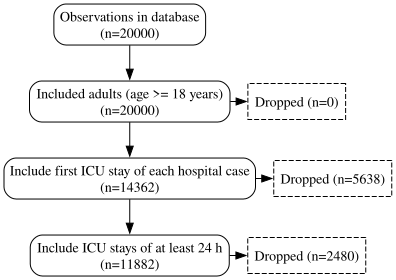

In [5]:
cohort.include_list(
    [
        {
            "variable": "age_on_admission",
            "operation": ">= 18",
            "label": "Adults",
            "operations_done": "adults (age >= 18 years)",
        },
    ]
)

# Number the ICU stays within each hospital case by admission time
cohort.obs = cohort.obs.with_columns(
    icu_stay_number=pl.col("icu_admission").rank("ordinal").over("case_id")
)
with cohort.change_tracker("first ICU stay of each hospital case") as track:
    track.filter(pl.col("icu_stay_number") == 1)

with cohort.change_tracker("ICU stays of at least 24 h") as track:
    track.filter(pl.col("icu_discharge") - pl.col("icu_admission") >= pl.duration(hours=24))

print(f"Study cohort: {len(cohort):,} ICU stays")
cohort.figureone

The source already restricts the dataset to adults by default (its
`filter.include_adults_only` option), so the first step removes nobody; it is kept here
because a protocol states it explicitly. `cohort.figureone` returns a graphviz object; use
`cohort.to_figureone().render("flowchart", format="pdf")` to save it.

```{note}
The 24-hour criterion is computed from the raw time stamps on purpose. The
`icu_length_of_stay` concept (next section) reports the length of stay in days with a
**floor of 1.0**, so `icu_length_of_stay >= 1` would keep every stay. Reading a concept's
definition before using it as a criterion pays off; see section 7.
```

## 3. Static variables

A *concept* is a curated, versioned variable definition. `cohort.add_variable(name)`
fetches the definition for this source from the Concepts API, runs it against the data and
stores the result. **Static** concepts (one value per stay) become columns of
`cohort.obs`:

In [6]:
for name in [
    "icu_length_of_stay",  # days
    "icu_admiss_type",  # surgical / medical
    "icu_admission_apache_iii",  # APACHE III admission diagnosis group
    "elix_total_vw",  # Elixhauser comorbidity index (van Walraven weights)
    "elixhauser_icd10_chf",  # congestive heart failure (Elixhauser ICD-10 codes)
]:
    cohort.add_variable(name)

cohort.obs.select(
    "icu_stay_id",
    "age_on_admission",
    "icu_length_of_stay",
    "icu_admiss_type",
    "icu_admission_apache_iii",
    "elix_total_vw",
    "elixhauser_icd10_chf",
).sort("icu_stay_id").head(5)

icu_stay_id,age_on_admission,icu_length_of_stay,icu_admiss_type,icu_admission_apache_iii,elix_total_vw,elixhauser_icd10_chf
str,i64,f64,str,str,i64,bool
"""0040000000_1""",59,2.682639,"""medical""","""Gastrointestinal""",0,false
"""0040000002_1""",75,1.682639,"""surgical""","""Cardiovascular""",5,false
"""0040000003_1""",44,9.554861,"""surgical""","""Neurologic""",-3,false
"""0040000005_1""",70,4.334722,"""medical""","""Cardiovascular""",-2,false
"""0040000006_1""",65,5.361806,"""medical""","""Gastrointestinal""",-5,false


`age_on_admission` needs no `add_variable` call: it is part of the cohort frame from the
start, like `sex` and `inhospital_death`.

Some concepts bring companion columns. `elix_total_vw` adds `elix_total_vw_detail`, a
struct with one 0/1 flag per Elixhauser comorbidity group. Unnesting it gives the
prevalence of each group:

In [7]:
(
    cohort.obs.select(pl.col("elix_total_vw_detail").struct.unnest())
    .mean()
    .transpose(include_header=True, header_name="comorbidity", column_names=["share"])
    .sort("share", descending=True)
    .head(8)
)

comorbidity,share
str,f64
"""Hypertension uncomplicated""",0.357095
"""Fluid and electrolyte disorder…",0.324188
"""Cardiac arrhythmias""",0.293217
"""Congestive heart failure""",0.24777
"""Chronic pulmonary disease""",0.176233
"""Solid tumor without metastasis""",0.162346
"""Obesity""",0.142484
"""Renal failure""",0.141474


```{note}
`elix_total_vw` is computed from the diagnoses time-stamped *inside* the observation
window. In this dataset, diagnoses are coded during the first ICU stay of a case, so a
later ICU stay of the same case has no diagnoses and gets a null score (about 23 % of all
ICU stays). Restricting the cohort to the first ICU stay per case removes them:
```

In [8]:
print(f"elix_total_vw missing: {cohort.obs['elix_total_vw'].null_count():,} of {len(cohort):,} stays")

elix_total_vw missing: 0 of 11,882 stays


Not every concept is a single value. `dx_diabetes_mellitus_any` returns **every matching
diagnosis** with its time stamp, so it lands in `cohort.obsm`, the dictionary of
time-series variables:

In [9]:
cohort.add_variable("dx_diabetes_mellitus_any")
cohort.obsm["dx_diabetes_mellitus_any"].select(
    "icu_stay_id", "recordtime", "value"
).sort("icu_stay_id").head(5)

icu_stay_id,recordtime,value
str,datetime[μs],str
"""0040000002_1""",2019-01-03 16:38:00,"""E11.72"""
"""0040000005_1""",2019-01-03 12:34:00,"""E10.20"""
"""0040000007_1""",2019-01-11 08:58:00,"""E11.91"""
"""0040000010_1""",2019-01-04 06:07:00,"""E10.20"""
"""0040000011_1""",2019-01-03 23:46:00,"""E11.90"""


To turn an event list into one value per stay, wrap it in an aggregation variable.
`NativeStatic` takes a `base_var`, an aggregation in `select` and a time window. Here
`"!any"` asks "is there at least one matching diagnosis during the hospital case?":

In [10]:
from corr_vars.sources.charite_demo import NativeStatic

cohort.add_variable(
    NativeStatic(
        "diabetes",
        select="!any",
        base_var="dx_diabetes_mellitus_any",
        tmin="hospital_admission",
        tmax="hospital_discharge",
    )
)
cohort.obs["diabetes"].value_counts(sort=True)

diabetes,count
bool,u32
false,9119
true,2763


## 4. Time series and time windows

**Dynamic** concepts return one row per measurement or per interval, with the columns
`recordtime` (and `recordtime_end` for intervals), `value`, `value_unit` and
`attributes` (a struct with concept-specific details). `recordtime_relative` is the time
in seconds since ICU admission.

By default a dynamic variable covers the observation itself, here from `icu_admission` to
`icu_discharge`. Mean arterial pressure is the largest concept in the demo (about
19 million invasive and non-invasive readings for all ICU stays), so this cell takes
roughly 10–20 seconds:

In [11]:
cohort.add_variable("blood_pressure_mean")
cohort.add_variable("norepinephrine")

cohort.obsm["norepinephrine"].select(
    "icu_stay_id",
    "recordtime",
    "recordtime_end",
    "value",
    "value_unit",
    pl.col("attributes").struct.field("rate_value", "rate_unit"),
).sort("icu_stay_id", "recordtime").head(5)

icu_stay_id,recordtime,recordtime_end,value,value_unit,rate_value,rate_unit
str,datetime[μs],datetime[μs],f64,str,str,str
"""0040000002_1""",2019-01-02 13:38:00,2019-01-02 14:38:00,0.2439,"""mg""","""0.06""","""µg/kg/min"""
"""0040000002_1""",2019-01-02 14:38:00,2019-01-02 15:38:00,0.2846,"""mg""","""0.07""","""µg/kg/min"""
"""0040000002_1""",2019-01-02 15:38:00,2019-01-02 16:38:00,0.2033,"""mg""","""0.05""","""µg/kg/min"""
"""0040000002_1""",2019-01-02 16:38:00,2019-01-02 17:38:00,0.122,"""mg""","""0.03""","""µg/kg/min"""
"""0040000005_1""",2019-01-01 12:53:00,2019-01-01 13:53:00,1.5405,"""mg""","""0.25""","""µg/kg/min"""


For norepinephrine, `value` is the amount given per charted interval (mg), and the
infusion rate as charted (µg/kg/min) sits in `attributes`.

### Derived concepts resolve their dependencies

The P/F ratio (PaO₂ / FiO₂) is not charted anywhere. Its definition *requires* two other
concepts, arterial PaO₂ (`blood_pao2_arterial`) and the FiO₂ setting (`vent_fio2`), and
pairs each blood gas with the closest FiO₂. `corr_vars` fetches and extracts the
requirements (and theirs, recursively) on its own:

In [12]:
pf = cohort.add_variable("pf_ratio")
pf.variables["charite_demo"].requirements

{'blood_pao2_arterial': {'template': 'blood_pao2_arterial',
  'tmin': 'inherit',
  'tmax': 'inherit'},
 'vent_fio2': {'template': 'vent_fio2', 'tmin': 'inherit', 'tmax': 'inherit'}}

Every definition that was used, including the indirect ones, is recorded with its
version in `cohort.concept_versions`. This is what makes a cohort reproducible: you can
see (and later pin) exactly which version of each definition built it.

In [13]:
pl.DataFrame(
    [
        {"concept": name, "version": r["version"], "status": r["status"]}
        for name, records in cohort.concept_versions.items()
        for r in records
    ]
)

concept,version,status
str,i64,str
"""icu_length_of_stay""",2,"""published"""
"""icu_admiss_type""",1,"""published"""
"""any_surgery_ops""",1,"""published"""
"""surgery_ops""",1,"""published"""
"""icu_admission_apache_iii""",1,"""published"""
…,…,…
"""fio2_set""",1,"""published"""
"""fio2_set_helper""",1,"""published"""
"""ventilator_mode_automatic_stan…",1,"""published"""


In [14]:
for name in ["invasive_vent", "endotracheal_tube", "sofa_score_total"]:
    cohort.add_variable(name)

cohort.obsm["invasive_vent"].select(
    "icu_stay_id", "recordtime", "recordtime_end", "value", "value_unit", "attributes"
).sort("icu_stay_id", "recordtime").head(5)

icu_stay_id,recordtime,recordtime_end,value,value_unit,attributes
str,datetime[μs],datetime[μs],f64,str,str
"""0040000000_1""",2019-01-01 23:04:00,2019-01-03 00:18:00,25.233333,"""hours""","""endotracheal"""
"""0040000002_1""",2019-01-02 08:52:00,2019-01-02 14:56:00,6.066667,"""hours""","""endotracheal"""
"""0040000003_1""",2019-01-01 13:30:00,2019-01-10 17:43:00,220.216667,"""hours""","""endotracheal"""
"""0040000005_1""",2019-01-03 03:14:00,2019-01-05 18:32:00,63.3,"""hours""","""endotracheal"""
"""0040000010_1""",2019-01-02 00:33:00,2019-01-05 22:11:00,93.633333,"""hours""","""endotracheal"""


`invasive_vent` has one row per ventilation episode (start, end, duration in hours, and
the airway in `attributes`); `endotracheal_tube` holds the tube insertions and removals;
`sofa_score_total` holds the daily SOFA scores.

### From time series to analysis features

An analysis usually needs one value per stay: the worst P/F in the first 24 hours, the
lowest MAP, whether norepinephrine was running. Two arguments define such a feature:

- **the aggregation** (`select`): `!first`, `!last`, `!min`, `!max`, `!mean`, `!median`,
  `!sum`, `!count`, `!any`, `!perc(q)`, `!closest(...)`, `!sum_interval`
  (see {doc}`../api/aggregation`);
- **the time window** (`tmin`, `tmax`): a column of `cohort.obs`, or a
  `(column, offset)` tuple such as `("icu_admission", "+24h")`.

```{important}
Always pass `tmin` and `tmax` to `NativeStatic`. Without them the window is
**unbounded** and the aggregation runs over everything the base variable returns, not
just this ICU stay.
```

In [15]:
first_24h = {"tmin": "icu_admission", "tmax": ("icu_admission", "+24h")}
whole_icu_stay = {"tmin": "icu_admission", "tmax": "icu_discharge"}

features = [
    NativeStatic("pf_worst_24h", select="!min value", base_var="pf_ratio", **first_24h),
    NativeStatic("map_lowest_24h", select="!min value", base_var="blood_pressure_mean", **first_24h),
    NativeStatic("norepinephrine_24h", select="!any", base_var="norepinephrine", **first_24h),
    NativeStatic("invasive_vent_24h", select="!any", base_var="invasive_vent", **first_24h),
    NativeStatic("sofa_first", select="!first value", base_var="sofa_score_total", **first_24h),
    NativeStatic("sofa_max", select="!max value", base_var="sofa_score_total", **whole_icu_stay),
    NativeStatic("vent_hours_icu", select="!sum_interval value", base_var="invasive_vent", **whole_icu_stay),
]
for feature in features:
    cohort.add_variable(feature)

cohort.obs.select(
    "pf_worst_24h", "map_lowest_24h", "norepinephrine_24h", "invasive_vent_24h",
    "sofa_first", "sofa_max", "vent_hours_icu",
).describe()

statistic,pf_worst_24h,map_lowest_24h,norepinephrine_24h,invasive_vent_24h,sofa_first,sofa_max,vent_hours_icu
str,f64,f64,f64,f64,f64,f64,f64
"""count""",5613.0,11882.0,11882.0,11882.0,11766.0,11871.0,11882.0
"""null_count""",6269.0,0.0,0.0,0.0,116.0,11.0,0.0
"""mean""",205.193642,65.383016,0.47896,0.255008,8.635475,8.816528,34.957709
"""std""",63.973246,9.37471,null,null,3.233899,3.367249,84.61143
"""min""",37.0,38.0,0.0,0.0,0.0,0.0,0.0
"""25%""",161.290323,58.0,null,null,6.0,6.0,0.0
"""50%""",209.210526,64.0,null,null,8.0,9.0,0.033333
"""75%""",253.225806,72.0,null,null,11.0,11.0,33.1
"""max""",433.448276,100.0,1.0,1.0,20.0,20.0,1675.85


`!sum_interval` sums interval values weighted by how much of each interval falls inside
the window, so a ventilation episode that started in the operating room counts only with
its ICU hours.

Anything the aggregation syntax does not cover is a few lines of polars on
`cohort.obsm`. The highest norepinephrine **rate** in the first 24 hours, for example,
lives in the `attributes` struct:

In [16]:
norepi_max_rate = (
    cohort.obsm["norepinephrine"]
    .filter(pl.col("recordtime_relative").is_between(0, 24 * 3600))
    .group_by("icu_stay_id")
    .agg(
        pl.col("attributes")
        .struct.field("rate_value")
        .cast(pl.Float64, strict=False)
        .max()
        .alias("norepi_max_rate_24h")
    )
)
cohort.obs = cohort.obs.join(norepi_max_rate, on="icu_stay_id", how="left")
cohort.obs["norepi_max_rate_24h"].describe()

statistic,value
str,f64
"""count""",5691.0
"""null_count""",6191.0
"""mean""",0.258216
"""std""",0.15796
"""min""",0.03
"""25%""",0.15
"""50%""",0.22
"""75%""",0.33
"""max""",1.52


## 5. Outcomes

### Acute kidney injury

The demo has both KDIGO criteria as hourly or per-sample stage series: creatinine-based
(`aki_crea_based`) and urine-output-based (`aki_urine_output`). Stage `-1` marks
dialysis-dependent chronic kidney disease (not assessable). The outcome is the highest
stage reached during the ICU stay by either criterion:

In [17]:
for feature in [
    NativeStatic("aki_crea_max", select="!max value", base_var="aki_crea_based", **whole_icu_stay),
    NativeStatic("aki_uo_max", select="!max value", base_var="aki_urine_output", **whole_icu_stay),
]:
    cohort.add_variable(feature)

aki_labels = {-1: "Dialysis-dependent CKD", 0: "No AKI", 1: "Stage 1", 2: "Stage 2", 3: "Stage 3"}
cohort.obs = cohort.obs.with_columns(
    aki_stage_max=pl.when(pl.min_horizontal("aki_crea_max", "aki_uo_max") == -1)
    .then(-1)
    .otherwise(pl.max_horizontal("aki_crea_max", "aki_uo_max"))
)
cohort.obs.group_by("aki_stage_max").len().sort("aki_stage_max").with_columns(
    pl.col("aki_stage_max").replace_strict(aki_labels, default=None).alias("label")
)

aki_stage_max,len,label
i32,u32,str
-1,365,"""Dialysis-dependent CKD"""
0,6320,"""No AKI"""
1,1771,"""Stage 1"""
2,1674,"""Stage 2"""
3,1752,"""Stage 3"""


`inhospital_death` is already in `cohort.obs`. For outcomes over a fixed horizon (for
example ventilator-free days to day 28) see `Cohort.add_horizon_variable`.

### Surgical patients: anchoring the window at hospital admission

About a third of the ICU admissions in the demo follow surgery. The anaesthesia record
(ASA physical status, urgency of the operation) is charted in the operating room, i.e.
**before** ICU admission. With the default window, which starts at ICU admission, these
concepts are almost empty:

In [18]:
cohort.add_variable("asa_physical_status")
n_with_asa = cohort.obsm["asa_physical_status"]["icu_stay_id"].n_unique()
print(f"ASA within the ICU stay: {n_with_asa:,} of {len(cohort):,} stays")

ASA within the ICU stay: 572 of 11,882 stays


A window from hospital admission to ICU admission captures the operation that led to the
ICU stay. `!last` keeps the most recent record before the ICU admission:

In [19]:
before_icu = {"tmin": "hospital_admission", "tmax": "icu_admission"}

for feature in [
    NativeStatic("surgery_before_icu", select="!any", base_var="surgery", **before_icu),
    NativeStatic("asa", select="!last value", base_var="asa_physical_status", **before_icu),
    NativeStatic("surgery_urgency_last", select="!last value", base_var="surgery_urgency", **before_icu),
]:
    cohort.add_variable(feature)

(
    cohort.obs.filter(pl.col("icu_admiss_type") == "surgical")
    .group_by("asa")
    .len()
    .sort("asa")
)

asa,len
i64,u32
null,425
2,686
3,1652
4,1471
5,315


In [20]:
(
    cohort.obs.group_by("icu_admiss_type", "surgery_before_icu")
    .len()
    .sort("icu_admiss_type", "surgery_before_icu")
)

icu_admiss_type,surgery_before_icu,len
str,bool,u32
"""medical""",false,7333
"""surgical""",false,425
"""surgical""",true,4124


`surgery_urgency` uses the Charité coding `N0`–`N5`, where `N0` is an elective operation
and `N1`–`N5` are emergency categories of increasing urgency.

## 6. Table 1 and plots

`cohort.to_tableone()` builds a [TableOne](https://tableone.readthedocs.io) from
`cohort.obs` (or from a DataFrame you pass). Numeric columns are summarised as median
[Q1, Q3], booleans and strings as counts. Preparing a small, labelled frame first gives a
clean table:

In [21]:
table_df = cohort.obs.select(
    pl.when(pl.col("invasive_vent_24h"))
    .then(pl.lit("Ventilated in first 24 h"))
    .otherwise(pl.lit("Not ventilated"))
    .alias("group"),
    "age_on_admission",
    pl.col("sex").replace_strict({"F": "female", "M": "male"}),
    "icu_admiss_type",
    "elix_total_vw",
    "elixhauser_icd10_chf",
    "diabetes",
    "sofa_first",
    "pf_worst_24h",
    "map_lowest_24h",
    "norepinephrine_24h",
    "vent_hours_icu",
    pl.col("aki_stage_max").replace_strict(aki_labels, default=None, return_dtype=pl.Utf8),
    "icu_length_of_stay",
    "inhospital_death",
)

table1 = cohort.to_tableone(
    df=table_df,
    groupby="group",
    overall=True,
    order={"aki_stage_max": list(aki_labels.values())},
    rename={
        "age_on_admission": "Age, years",
        "sex": "Sex",
        "icu_admiss_type": "ICU admission type",
        "elix_total_vw": "Elixhauser index (van Walraven)",
        "elixhauser_icd10_chf": "Congestive heart failure",
        "diabetes": "Diabetes mellitus",
        "sofa_first": "SOFA, first 24 h",
        "pf_worst_24h": "Worst P/F, first 24 h, mmHg",
        "map_lowest_24h": "Lowest MAP, first 24 h, mmHg",
        "norepinephrine_24h": "Norepinephrine, first 24 h",
        "vent_hours_icu": "Invasive ventilation in ICU, h",
        "aki_stage_max": "Highest AKI stage in ICU",
        "icu_length_of_stay": "ICU length of stay, days",
        "inhospital_death": "In-hospital death",
    },
)
table1

Grouped by group                                                                   
                                                                                Missing              Overall       Not ventilated Ventilated in first 24 h
n                                                                                                      11882                 8852                     3030
Age, years, median [Q1,Q3]                                                            0     68.0 [58.0,76.0]     68.0 [58.0,76.0]         68.0 [58.0,76.0]
Sex, n (%)                                      female                                           4591 (38.6)          3448 (39.0)              1143 (37.7)
                                                male                                             7291 (61.4)          5404 (61.0)              1887 (62.3)
ICU admission type, n (%)                       medical                                          7333 (61.7)          4713 (53.2)              2620 (86.5)
                                                surgical                                         4549 (38.3)          4139 (46.8)               410 (13.5)
Elixhauser index (van Walraven), median [Q1,Q3]                                       0       7.0 [3.0,12.0]       7.0 [3.0,12.0]           7.0 [2.0,12.0]
Congestive heart failure, n (%)                 Yes                                              2944 (24.8)          2168 (24.5)               776 (25.6)
                                                No                                               8938 (75.2)          6684 (75.5)              2254 (74.4)
Diabetes mellitus, n (%)                        Yes                                              2763 (23.3)          2095 (23.7)               668 (22.0)
                                                No                                               9119 (76.7)          6757 (76.3)              2362 (78.0)
SOFA, first 24 h, median [Q1,Q3]                                                    116       8.0 [6.0,11.0]       8.0 [6.0,10.0]          11.0 [9.0,13.0]
Worst P/F, first 24 h, mmHg, median [Q1,Q3]                                        6269  209.2 [161.3,253.2]  240.3 [202.9,263.7]      171.6 [127.7,220.3]
Lowest MAP, first 24 h, mmHg, median [Q1,Q3]                                          0     64.0 [58.0,72.0]     66.0 [60.0,74.0]         59.0 [56.0,64.0]
Norepinephrine, first 24 h, n (%)               Yes                                              5691 (47.9)          3539 (40.0)              2152 (71.0)
                                                No                                               6191 (52.1)          5313 (60.0)               878 (29.0)
Invasive ventilation in ICU, h, median [Q1,Q3]                                        0       0.0 [0.0,33.1]        0.0 [0.0,1.3]        64.2 [29.3,136.5]
Highest AKI stage in ICU, n (%)                 Dialysis-dependent CKD                             365 (3.1)            275 (3.1)                 90 (3.0)
                                                No AKI                                           6320 (53.2)          5158 (58.3)              1162 (38.3)
                                                Stage 1                                          1771 (14.9)          1246 (14.1)               525 (17.3)
                                                Stage 2                                          1674 (14.1)          1102 (12.4)               572 (18.9)
                                                Stage 3                                          1752 (14.7)          1071 (12.1)               681 (22.5)
ICU length of stay, days, median [Q1,Q3]                                              0        3.1 [1.8,6.1]        2.7 [1.7,5.0]            5.0 [2.7,9.5]
In-hospital death, n (%)                        Yes                                              1659 (14.0)           881 (10.0)               778 (25.7)
                                         

The P/F ratio needs a charted FiO₂, which exists mainly for patients on a ventilator or a
high-flow device; hence the many missing values. `In-hospital death` is unknown (`None`)
for cases that were still open on the dataset's reference date (31 Dec 2025). To use the table in a manuscript, export it:
`table1.to_excel("table1.xlsx")`, or with the helpers in `corr_vars.utils`:
`tableone_to_latex`, `tableone_to_markdown`, `tableone_to_html`, `tableone_to_pdf`.

### Plot 1: oxygenation over the first three days

Median and interquartile range of the P/F ratio in 6-hour bins, for patients ventilated
within 24 hours, by survival:

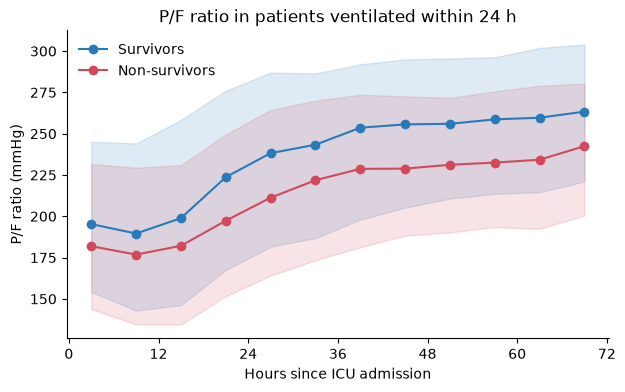

In [22]:
ventilated = cohort.obs.filter(pl.col("invasive_vent_24h")).select("icu_stay_id", "inhospital_death")

pf_course = (
    cohort.obsm["pf_ratio"]
    .join(ventilated, on="icu_stay_id")
    .filter(pl.col("recordtime_relative").is_between(0, 72 * 3600, closed="left"))
    .with_columns(hour=(pl.col("recordtime_relative") // (6 * 3600)) * 6 + 3)
    .group_by("inhospital_death", "hour")
    .agg(
        pl.col("value").median().alias("median"),
        pl.col("value").quantile(0.25).alias("q1"),
        pl.col("value").quantile(0.75).alias("q3"),
    )
    .drop_nulls("inhospital_death")
    .sort("hour")
)

fig, ax = plt.subplots(figsize=(7, 4))
for died, label, color in [(False, "Survivors", "#2a7ab9"), (True, "Non-survivors", "#d1495b")]:
    d = pf_course.filter(pl.col("inhospital_death") == died)
    ax.plot(d["hour"], d["median"], marker="o", color=color, label=label)
    ax.fill_between(d["hour"], d["q1"], d["q3"], color=color, alpha=0.15)
ax.set(
    xlabel="Hours since ICU admission",
    ylabel="P/F ratio (mmHg)",
    xticks=range(0, 73, 12),
    title="P/F ratio in patients ventilated within 24 h",
)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Plot 2: blood pressure and norepinephrine in one stay

Time series are easiest to sanity-check one patient at a time. Here, the ventilated stay
with the highest norepinephrine rate in the first 24 hours:

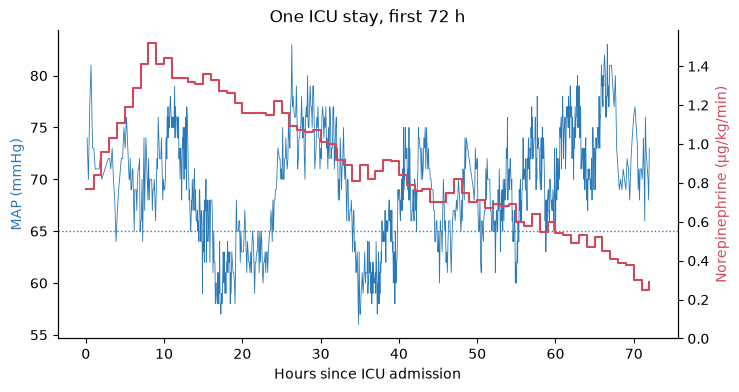

In [23]:
stay_id = (
    cohort.obs.filter(pl.col("invasive_vent_24h"))
    .sort("norepi_max_rate_24h", "icu_stay_id", descending=[True, False], nulls_last=True)
    .item(0, "icu_stay_id")
)
hours = (pl.col("recordtime_relative") / 3600).alias("hours")
window = pl.col("recordtime_relative").is_between(0, 72 * 3600)

map_stay = cohort.obsm["blood_pressure_mean"].filter(
    (pl.col("icu_stay_id") == stay_id) & window
).select(hours, "value")
norepi_stay = cohort.obsm["norepinephrine"].filter(
    (pl.col("icu_stay_id") == stay_id) & window
).select(
    hours,
    pl.col("attributes").struct.field("rate_value").cast(pl.Float64, strict=False).alias("rate"),
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(map_stay["hours"], map_stay["value"], color="#2a7ab9", linewidth=0.6)
ax.axhline(65, color="#2a7ab9", linestyle=":", linewidth=1)
ax.set(xlabel="Hours since ICU admission", ylabel="MAP (mmHg)", title="One ICU stay, first 72 h")
ax.yaxis.label.set_color("#2a7ab9")
ax2 = ax.twinx()
ax2.step(norepi_stay["hours"], norepi_stay["rate"], where="post", color="#d1495b")
ax2.set_ylabel("Norepinephrine (µg/kg/min)", color="#d1495b")
ax2.set_ylim(bottom=0)
for a in (ax, ax2):
    a.spines[["top"]].set_visible(False)
plt.show()

### Plot 3: highest AKI stage by early ventilation

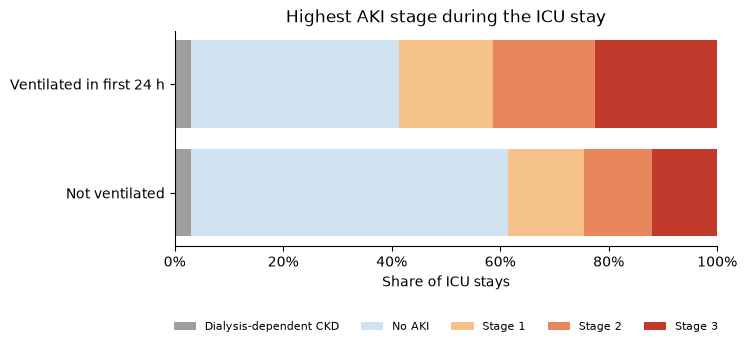

In [24]:
aki_share = (
    table_df.drop_nulls("aki_stage_max")
    .group_by("group", "aki_stage_max")
    .len()
    .with_columns(share=pl.col("len") / pl.col("len").sum().over("group"))
)

stages = list(aki_labels.values())
groups = ["Not ventilated", "Ventilated in first 24 h"]
colors = ["#9e9e9e", "#cfe3f1", "#f6c28b", "#e8875b", "#c0392b"]

fig, ax = plt.subplots(figsize=(7, 2.8))
left = [0.0, 0.0]
for stage, color in zip(stages, colors):
    widths = [
        aki_share.filter((pl.col("group") == g) & (pl.col("aki_stage_max") == stage))["share"].sum()
        for g in groups
    ]
    ax.barh(groups, widths, left=left, color=color, label=stage)
    left = [l + w for l, w in zip(left, widths)]
ax.set(xlim=(0, 1), xlabel="Share of ICU stays", title="Highest AKI stage during the ICU stay")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(ncols=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.3), fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 7. Where does a variable come from? And exporting

### Inspecting a definition

Each concept's definition is open. In the browser, look a concept up in the
[demo Concepts Browser](https://demo-concepts.corr.icu) (sign in as `demo`), e.g.
[`pf_ratio`](https://demo-concepts.corr.icu/concepts/tax/corr_v1/pf_ratio): its
documentation, the source-specific configuration, the Python code, and the full version
history.

From Python, the variable object returned by `add_variable` carries what was executed: the
requirements shown above and, for concepts with code, the exact source text that ran:

In [25]:
print(pf.variables["charite_demo"].py.source[:900], "...")

def pf_ratio(
    var: VariableContext,
    cohort: Cohort,
    plusminus: pd.Timedelta = pd.Timedelta(hours=24),
    strategy: AsofJoinStrategy = "nearest",
) -> pd.DataFrame:
    """
    Calculate the PF ratio by matching each PaO2 value to the closest FiO2 value within a specified time window,
    and filter PF ratios to keep only values between 10 and 1000.

    Args:
        var: VariableContext container with required data for PaO2 and FiO2.
        cohort: Cohort object containing the primary key.
        plusminus (pd.Timedelta): Optional time range within which to find the closest FiO2 for each PaO2.
                                  Defaults to 24 hours.
        strategy (str): Strategy for asof join - "nearest", "backward", or "forward". Defaults to "nearest".

    Returns:
        pd.DataFrame: DataFrame with the primary key, PaO2, closest FiO2, and calculated, cleaned PF rat ...


In [26]:
{k: v for k, v in cohort.concept_versions["pf_ratio"][0].items() if k != "endpoint"}

{'taxonomy': 'corr_v1',
 'name': 'pf_ratio',
 'source': 'charite_demo',
 'origin': 'api',
 'concept_id': 29,
 'requested': 'latest',
 'version': 1,
 'source_version': 1,
 'status': 'published',
 'committed_at': '2026-10-22T11:45:14.054017',
 'deprecated_at': None,
 'successor_id': None,
 'pointer_deprecated_at': None,
 'warning': None}

To freeze a study, pin the definitions: `Cohort(..., date="2026-10-22")` resolves every
concept (and every dependency) as of that day, and `add_variable("pf_ratio::v2")` pins a
single one.

### Exporting

`cohort.save()` writes the whole cohort, including all time series and the concept
versions, to one `.corr3` file that `Cohort.load()` reads back without network access.
For other tools, `to_parquet()`, `to_csv()` and `to_stata()` write `obs` and every
`obsm` table:

In [27]:
import tempfile
from pathlib import Path

export_dir = Path(tempfile.mkdtemp())

cohort.save(export_dir / "ventilation_study.corr3")
cohort.to_parquet(export_dir / "parquet")

sorted(p.relative_to(export_dir).as_posix() for p in export_dir.rglob("*") if p.is_file())

['parquet/_obs.parquet',
 'parquet/asa_physical_status.parquet',
 'parquet/blood_pressure_mean.parquet',
 'parquet/dx_diabetes_mellitus_any.parquet',
 'parquet/endotracheal_tube.parquet',
 'parquet/invasive_vent.parquet',
 'parquet/norepinephrine.parquet',
 'parquet/pf_ratio.parquet',
 'parquet/sofa_score_total.parquet',
 'ventilation_study.corr3']

In [28]:
reloaded = Cohort.load(export_dir / "ventilation_study.corr3")
print(f"Reloaded {len(reloaded):,} stays with {len(reloaded.obsm)} time-series variables")

Reloaded 11,882 stays with 8 time-series variables


## Where to go next

- {doc}`../tutorials`: the general tutorials (aggregation, multi-source cohorts, time
  series).
- {doc}`../custom_variables`: define your own variables.
- {doc}`../api/cohort`: the full `Cohort` API.
- The other demo concepts: browse them in the
  [demo Concepts Browser](https://demo-concepts.corr.icu).